# 04 — Aprendizaje no supervisado: estructura de las actividades humanas

Este notebook busca grupos en las 561 características de acelerómetro y giroscopio **sin utilizar la actividad real durante el ajuste**. Las etiquetas se consultan únicamente después de formar los grupos, para interpretar su correspondencia con las seis actividades.

**Algoritmos:** K-means y mezcla gaussiana (GMM). **Evaluación interna:** Silhouette Score. **Evaluación externa posterior:** ARI, NMI, pureza, correspondencia óptima y tablas de composición.

La estrategia responde tres preguntas:

1. ¿Cuántos grupos sugiere la geometría de los datos?
2. Si se fija `k=6`, ¿los grupos corresponden a las seis actividades reales?
3. ¿Los grupos aprendidos con 21 participantes se conservan en 9 participantes no vistos?

> La etiqueta no se incluye en PCA, K-means, GMM ni t-SNE. Colorear una gráfica o calcular métricas externas después del ajuste no convierte el entrenamiento en supervisado.

## 1. Bibliotecas y carga de datos

Se reutilizan los archivos procesados por `02_preprocesamiento.ipynb` cuando están disponibles. Como respaldo reproducible, también se admite la estructura original descargada de UCI en `evaluacion 4/data/`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from sklearn.mixture import GaussianMixture

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)

def localizar_data():
    candidatas = [Path('../data'), Path('data'), Path('evaluacion 4/data')]
    for ruta in candidatas:
        if ((ruta / 'procesado/train.pkl').exists() and
                (ruta / 'procesado/test.pkl').exists()):
            return ruta.resolve(), 'procesado'
        if ((ruta / 'train/X_train.txt').exists() and
                (ruta / 'test/X_test.txt').exists()):
            return ruta.resolve(), 'original'
    raise FileNotFoundError(
        'No se encontraron los datos. Descarga UCI HAR Dataset y copia su contenido '
        'en evaluacion 4/data/, o ejecuta antes 02_preprocesamiento.ipynb.')

def cargar_original(data_dir):
    leer = lambda archivo: pd.read_csv(data_dir / archivo, sep=r'\s+', header=None)
    nombres = leer('features.txt')[1]
    repeticion = nombres.groupby(nombres).cumcount()
    nombres_unicos = np.where(
        repeticion > 0, nombres + '_' + repeticion.astype(str), nombres)
    labels = leer('activity_labels.txt').set_index(0)[1]

    def cargar_particion(particion):
        X = leer(f'{particion}/X_{particion}.txt')
        X.columns = nombres_unicos
        y = leer(f'{particion}/y_{particion}.txt')[0].astype(int)
        sujeto = leer(f'{particion}/subject_{particion}.txt')[0].astype(int)
        info = pd.DataFrame({
            'actividad_id': y,
            'actividad': y.map(labels),
            'grupo': np.where(y.isin([1, 2, 3]), 'dinamica', 'estatica'),
            'persona': sujeto,
        })
        return pd.concat([X, info], axis=1)
    return cargar_particion('train'), cargar_particion('test')

data_dir, origen = localizar_data()
if origen == 'procesado':
    train = pd.read_pickle(data_dir / 'procesado/train.pkl')
    test = pd.read_pickle(data_dir / 'procesado/test.pkl')
else:
    train, test = cargar_original(data_dir)

auxiliares = ['actividad_id', 'actividad', 'grupo', 'persona']
assert all(c in train.columns and c in test.columns for c in auxiliares)
X_train = train.drop(columns=auxiliares)
X_test = test.drop(columns=auxiliares)
X = pd.concat([X_train, X_test], ignore_index=True)
info = pd.concat([train[auxiliares], test[auxiliares]], ignore_index=True)
y = info['actividad_id'].astype(int).to_numpy()
nombres = (info[['actividad_id', 'actividad']].drop_duplicates()
           .sort_values('actividad_id').set_index('actividad_id')['actividad'].to_dict())
orden_actividades = [nombres[i] for i in sorted(nombres)]

assert X.shape == (10299, 561)
assert not X.isna().any().any()
assert set(train['persona']).isdisjoint(set(test['persona']))
print('Origen:', origen, '| Directorio:', data_dir)
print('Matriz sin etiquetas:', X.shape)
print('Participantes:', info['persona'].nunique(),
      '| train:', train['persona'].nunique(), '| test:', test['persona'].nunique())
print('Actividades (solo para evaluación posterior):', orden_actividades)

Origen: original | Directorio: /Applications/MAMP/htdocs/analisis-datos-evento2-grupo7.1/evaluacion 4/data
Matriz sin etiquetas: (10299, 561)
Participantes: 30 | train: 21 | test: 9
Actividades (solo para evaluación posterior): ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


## 2. Dimensionalidad y representación con PCA

Las características de UCI ya están acotadas y normalizadas. Además, el preprocesamiento previo mostró que estandarizar cada columna perjudicaba el Silhouette Score; por eso se conserva la escala original y PCA se ajusta solo con `X`.

PCA reduce redundancia lineal y acelera los algoritmos. Se retienen componentes suficientes para explicar al menos 90 % de la varianza. La actividad real solo se usa después para colorear la proyección bidimensional.

Dimensión original: 561
Componentes para >= 90 %: 36
Varianza retenida: 90.217%
Varianza de PC1 + PC2: 67.000%


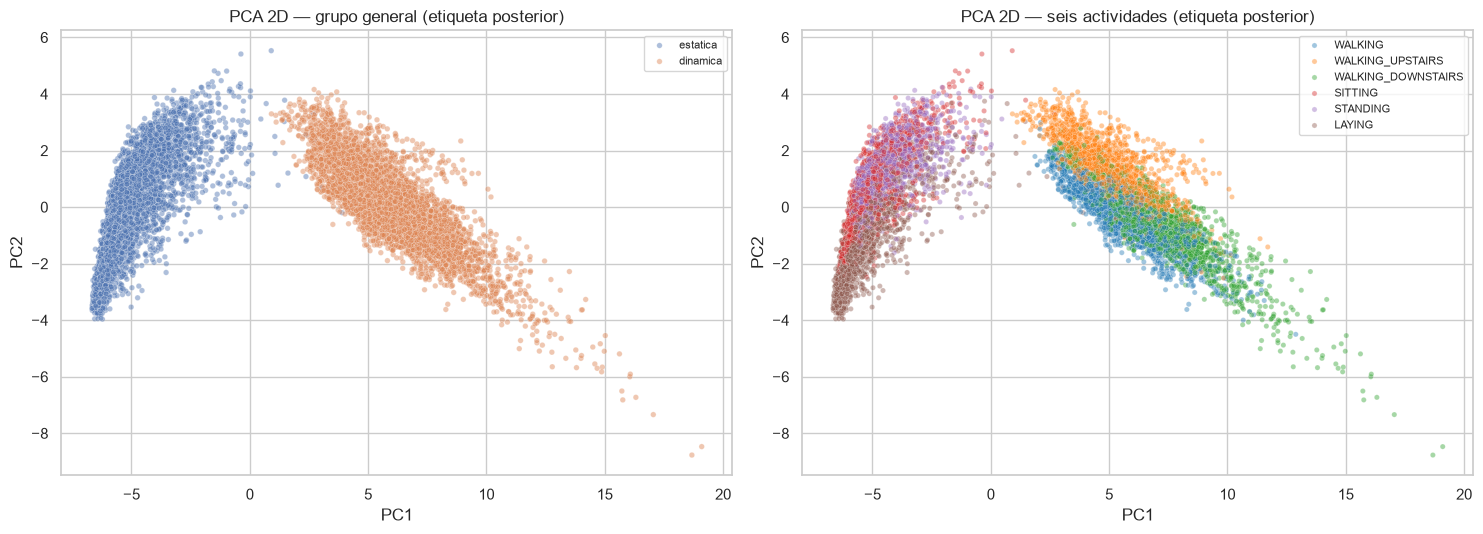

In [2]:
pca = PCA(n_components=0.90, random_state=SEED)
Z = pca.fit_transform(X)
pca_2d = PCA(n_components=2, random_state=SEED)
Z2 = pca_2d.fit_transform(X)

print('Dimensión original:', X.shape[1])
print('Componentes para >= 90 %:', pca.n_components_)
print('Varianza retenida:', f'{pca.explained_variance_ratio_.sum():.3%}')
print('Varianza de PC1 + PC2:', f'{pca_2d.explained_variance_ratio_.sum():.3%}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=info['grupo'],
                alpha=.45, s=16, ax=axes[0])
axes[0].set_title('PCA 2D — grupo general (etiqueta posterior)')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=info['actividad'],
                hue_order=orden_actividades, palette='tab10', alpha=.42,
                s=14, ax=axes[1])
axes[1].set_title('PCA 2D — seis actividades (etiqueta posterior)')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
for ax in axes:
    ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

## 3. ¿PCA conserva una geometría útil para agrupar?

Se compara K-means con `k=6` sobre las 561 variables y sobre PCA al 90 %. El Silhouette Score no requiere conocer la actividad y toma valores entre -1 y 1: cuanto mayor, más compactos y separados son los grupos. Se usa una muestra fija únicamente para calcular la métrica, no para entrenar.

In [3]:
comparacion_representacion = []
for representacion, datos in [('Original (561 variables)', X.to_numpy()),
                              (f'PCA 90 % ({Z.shape[1]} componentes)', Z)]:
    etiquetas_cluster = KMeans(
        n_clusters=6, n_init=20, random_state=SEED
    ).fit_predict(datos)
    sil = silhouette_score(datos, etiquetas_cluster, sample_size=2500,
                           random_state=SEED)
    comparacion_representacion.append({
        'Representación': representacion,
        'Dimensiones': datos.shape[1],
        'Silhouette k=6': sil,
    })

comparacion_representacion = pd.DataFrame(comparacion_representacion)
display(comparacion_representacion.round(4))

,Representación,Dimensiones,Silhouette k=6
0,Original (561 variables),561,0.1313
1,PCA 90 % (36 componentes),36,0.1716


## 4. Número de grupos y comparación de dos algoritmos

- **K-means** busca grupos aproximadamente esféricos y minimiza la distancia cuadrática a centroides.
- **Mezcla gaussiana (GMM)** modela cada grupo como una distribución probabilística; con covarianza diagonal permite distinta dispersión por componente sin estimar una matriz completa inestable.

Se exploran valores de `k=2` a `k=10` usando solo PCA y Silhouette. Conocer que el problema documenta seis actividades justifica comparar también `k=6`, pero no se usan las etiquetas para escoger parámetros ni formar grupos.

Algoritmo,K-means,Mezcla gaussiana
k,,
2,0.5348,0.5236
3,0.3689,0.2861
4,0.2305,0.1501
5,0.2082,0.1830
6,0.1716,0.1133
7,0.1573,0.1339
8,0.1442,0.0882
9,0.1512,0.0920
10,0.1461,0.0882


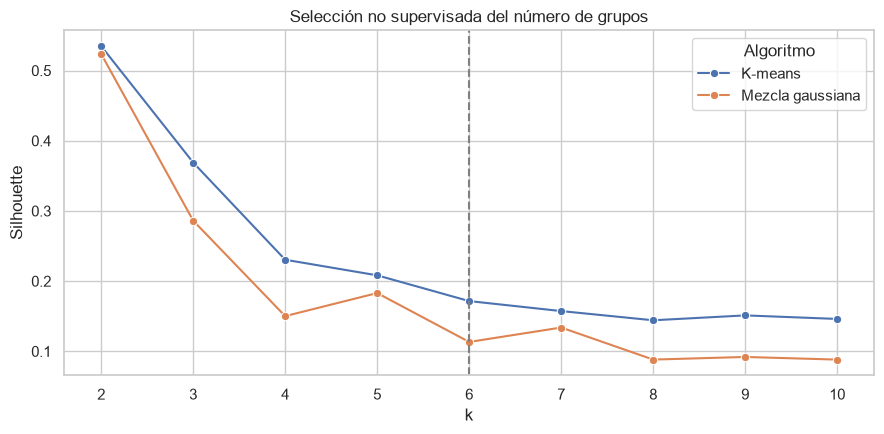

Mejor k según Silhouette (sin etiquetas):


,Algoritmo,k,Silhouette
0,K-means,2,0.5348
1,Mezcla gaussiana,2,0.5236


In [4]:
resultados_k = []
modelos_k2 = {}
modelos_k6 = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    grupos_km = km.fit_predict(Z)
    resultados_k.append({
        'Algoritmo': 'K-means', 'k': k,
        'Silhouette': silhouette_score(
            Z, grupos_km, sample_size=2500, random_state=SEED)
    })
    if k == 2:
        modelos_k2['K-means'] = (km, grupos_km)
    if k == 6:
        modelos_k6['K-means'] = (km, grupos_km)

    gmm = GaussianMixture(n_components=k, covariance_type='diag', n_init=2,
                          reg_covar=1e-5, random_state=SEED)
    grupos_gmm = gmm.fit_predict(Z)
    resultados_k.append({
        'Algoritmo': 'Mezcla gaussiana', 'k': k,
        'Silhouette': silhouette_score(
            Z, grupos_gmm, sample_size=2500, random_state=SEED)
    })
    if k == 2:
        modelos_k2['Mezcla gaussiana'] = (gmm, grupos_gmm)
    if k == 6:
        modelos_k6['Mezcla gaussiana'] = (gmm, grupos_gmm)

resultados_k = pd.DataFrame(resultados_k)
display(resultados_k.pivot(index='k', columns='Algoritmo',
                           values='Silhouette').round(4))

plt.figure(figsize=(9, 4.5))
sns.lineplot(data=resultados_k, x='k', y='Silhouette', hue='Algoritmo',
             marker='o')
plt.axvline(6, color='gray', linestyle='--', label='6 actividades conocidas')
plt.title('Selección no supervisada del número de grupos')
plt.xticks(range(2, 11))
plt.tight_layout()
plt.show()

mejores_k = (resultados_k.loc[resultados_k.groupby('Algoritmo')['Silhouette'].idxmax(),
                              ['Algoritmo', 'k', 'Silhouette']]
              .sort_values('Algoritmo'))
print('Mejor k según Silhouette (sin etiquetas):')
display(mejores_k.round(4))

## 5. Correspondencia con las actividades reales

Después del entrenamiento se comparan los grupos de `k=6` con la verdad conocida:

- **ARI** y **NMI** son invariantes al número asignado a cada cluster.
- **Pureza** indica qué fracción quedaría explicada por la clase mayoritaria de cada cluster; debe interpretarse con `k` fijo porque aumenta al crear más grupos.
- **Correspondencia óptima** empareja uno a uno clusters y actividades mediante el algoritmo húngaro. No es Accuracy de un clasificador.

Las etiquetas solo entran en estas métricas, nunca en el ajuste.

,Algoritmo,k,Silhouette,ARI,NMI,Pureza,Correspondencia óptima 1:1
0,K-means,6,0.1716,0.4612,0.5887,0.5994,0.5994
1,Mezcla gaussiana,6,0.1133,0.4140,0.5823,0.6269,0.5946


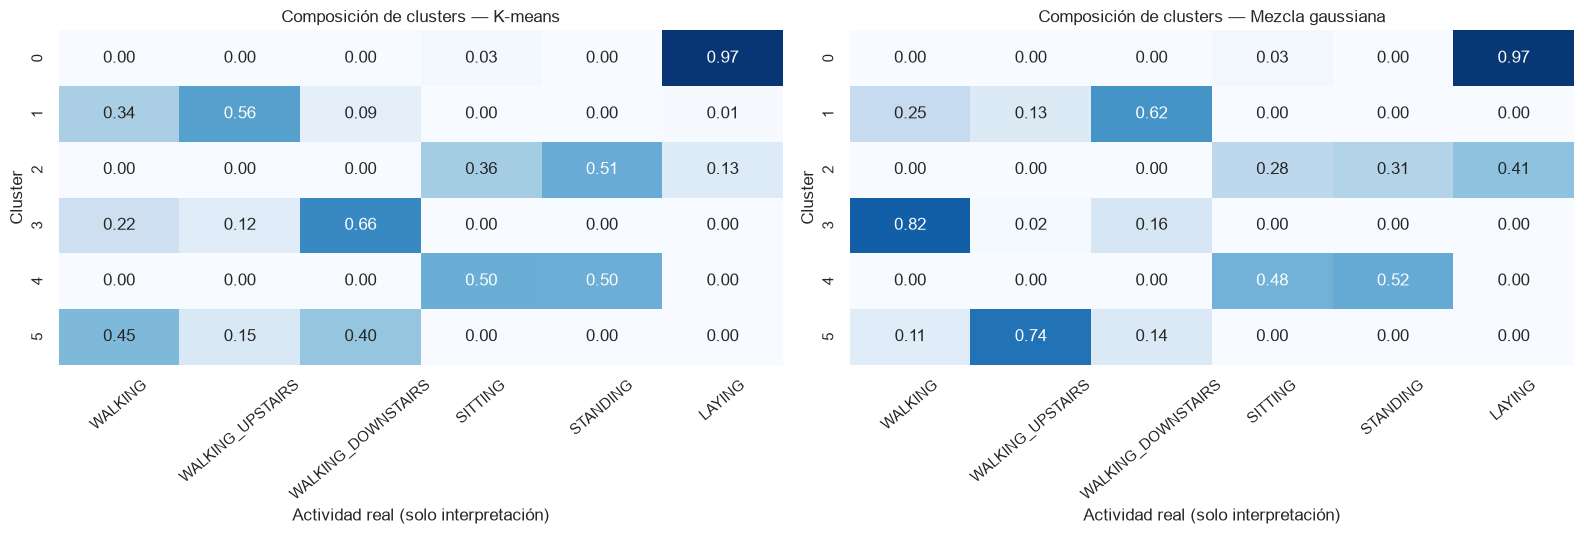

In [5]:
def evaluar_correspondencia(y_real, grupos):
    tabla = pd.crosstab(pd.Series(grupos, name='cluster'),
                        pd.Series(y_real, name='actividad_id'))
    pureza = tabla.max(axis=1).sum() / tabla.to_numpy().sum()
    filas, columnas = linear_sum_assignment(-tabla.to_numpy())
    correspondencia = tabla.to_numpy()[filas, columnas].sum() / len(y_real)
    return {
        'ARI': adjusted_rand_score(y_real, grupos),
        'NMI': normalized_mutual_info_score(y_real, grupos),
        'Pureza': pureza,
        'Correspondencia óptima 1:1': correspondencia,
    }

metricas_agrupamiento = []
composiciones = {}
for algoritmo, (_, grupos) in modelos_k6.items():
    fila = {'Algoritmo': algoritmo, 'k': 6,
            'Silhouette': resultados_k.query(
                'Algoritmo == @algoritmo and k == 6')['Silhouette'].iloc[0]}
    fila.update(evaluar_correspondencia(y, grupos))
    metricas_agrupamiento.append(fila)
    composicion = pd.crosstab(
        pd.Series(grupos, name='cluster'), info['actividad'], normalize='index'
    ).reindex(columns=orden_actividades, fill_value=0)
    composiciones[algoritmo] = composicion

metricas_agrupamiento = pd.DataFrame(metricas_agrupamiento)
display(metricas_agrupamiento.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (algoritmo, composicion) in zip(axes, composiciones.items()):
    sns.heatmap(composicion, annot=True, fmt='.2f', cmap='Blues',
                vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'Composición de clusters — {algoritmo}')
    ax.set_xlabel('Actividad real (solo interpretación)')
    ax.set_ylabel('Cluster')
    ax.tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.show()

### 5.1. ¿Los grupos separan mejor estático de dinámico?

Primero se compara el mejor resultado puramente interno (`k=2`) con las dos categorías amplias. Después se resume cada cluster de `k=6` por esas categorías. Un cluster puro en este nivel puede mezclar actividades individuales y, aun así, capturar correctamente el tipo general de movimiento.

Correspondencia de k=2 con estática/dinámica (evaluación posterior):


,Algoritmo,k,ARI,NMI,Pureza,Correspondencia óptima 1:1
0,K-means,2,0.9942,0.9856,0.9985,0.9985
1,Mezcla gaussiana,2,0.9403,0.9014,0.9849,0.9849


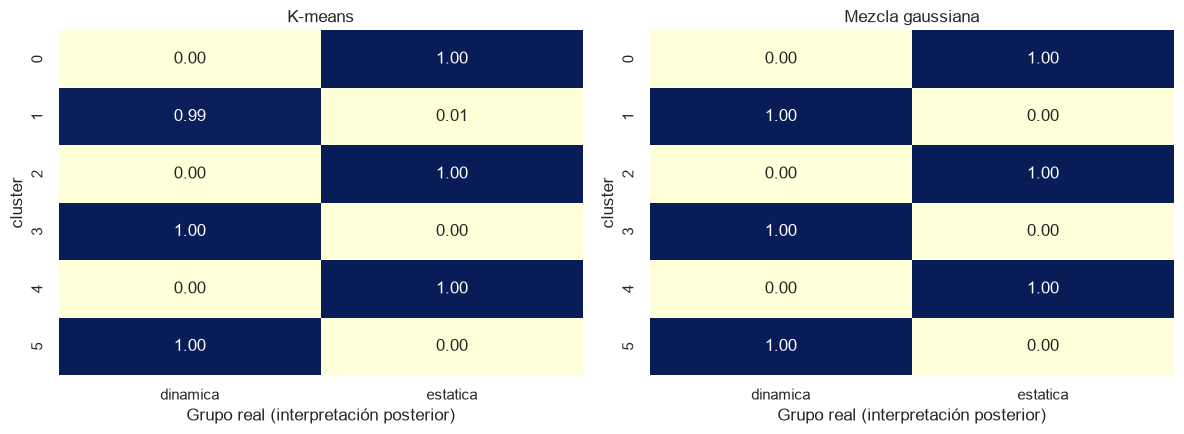

In [6]:
y_macro = info['grupo'].to_numpy()
metricas_macro_k2 = []
for algoritmo, (_, grupos) in modelos_k2.items():
    fila = {'Algoritmo': algoritmo, 'k': 2}
    fila.update(evaluar_correspondencia(y_macro, grupos))
    metricas_macro_k2.append(fila)
metricas_macro_k2 = pd.DataFrame(metricas_macro_k2)
print('Correspondencia de k=2 con estática/dinámica (evaluación posterior):')
display(metricas_macro_k2.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
composicion_macro_export = []
for ax, (algoritmo, (_, grupos)) in zip(axes, modelos_k6.items()):
    tabla_macro = pd.crosstab(
        pd.Series(grupos, name='cluster'), info['grupo'], normalize='index'
    ).reindex(columns=['dinamica', 'estatica'], fill_value=0)
    sns.heatmap(tabla_macro, annot=True, fmt='.2f', cmap='YlGnBu',
                vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(algoritmo)
    ax.set_xlabel('Grupo real (interpretación posterior)')
    for cluster, fila in tabla_macro.iterrows():
        composicion_macro_export.append({
            'Algoritmo': algoritmo, 'cluster': cluster,
            'proporcion_dinamica': fila['dinamica'],
            'proporcion_estatica': fila['estatica'],
        })
plt.tight_layout()
plt.show()

## 6. PCA frente a una representación visual no lineal

PCA 2D conserva ejes globales y es reproducible, pero comprime en dos dimensiones una estructura de muchas variables. t-SNE prioriza vecindades locales y puede revelar subgrupos curvos, aunque sus distancias globales, tamaños y espacios vacíos no deben interpretarse literalmente.

Para mantener un tiempo razonable se toma una muestra aleatoria —sin consultar las etiquetas— y t-SNE recibe los componentes PCA al 90 %. La métrica de *trustworthiness* cuantifica cuánto se conservan los vecinos del espacio reducido.

Trustworthiness PCA 2D:  0.8941
Trustworthiness t-SNE 2D: 0.9895


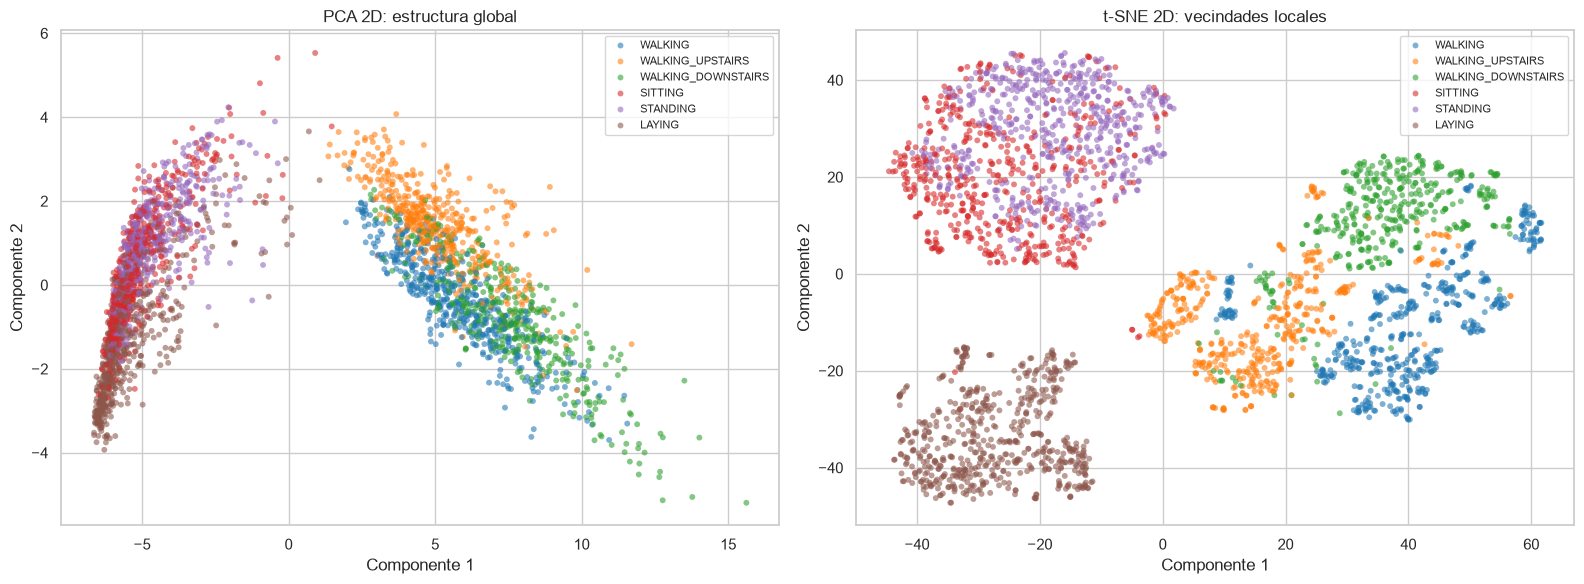

In [7]:
rng = np.random.default_rng(SEED)
idx_visual = np.sort(rng.choice(len(Z), size=3000, replace=False))
Z_muestra = Z[idx_visual]
Z2_muestra = Z2[idx_visual]
tsne = TSNE(n_components=2, perplexity=40, init='pca',
            learning_rate='auto', max_iter=1000, random_state=SEED)
T2 = tsne.fit_transform(Z_muestra)

conf_pca = trustworthiness(Z_muestra, Z2_muestra, n_neighbors=10)
conf_tsne = trustworthiness(Z_muestra, T2, n_neighbors=10)
print(f'Trustworthiness PCA 2D:  {conf_pca:.4f}')
print(f'Trustworthiness t-SNE 2D: {conf_tsne:.4f}')

actividad_visual = info.iloc[idx_visual]['actividad'].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, datos, titulo in [
    (axes[0], Z2_muestra, 'PCA 2D: estructura global'),
    (axes[1], T2, 't-SNE 2D: vecindades locales')
]:
    sns.scatterplot(x=datos[:, 0], y=datos[:, 1], hue=actividad_visual,
                    hue_order=orden_actividades, palette='tab10', alpha=.58,
                    s=18, linewidth=0, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel('Componente 1'); ax.set_ylabel('Componente 2')
    ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

## 7. Generalización a participantes no vistos

El análisis anterior describe toda la colección. Para una prueba más exigente, PCA y cada algoritmo se ajustan **solo con los 21 participantes de entrenamiento**. Luego se asignan clusters a las ventanas de los 9 participantes oficiales de prueba. No se usan sus etiquetas ni sus señales al ajustar.

Esta prueba sí mide transferencia entre usuarios para los métodos que permiten asignar observaciones nuevas. Sigue sin ser clasificación: los clusters no reciben nombres durante el entrenamiento.

In [8]:
pca_train = PCA(n_components=0.90, random_state=SEED)
Z_train = pca_train.fit_transform(X_train)
Z_test = pca_train.transform(X_test)
y_test = test['actividad_id'].astype(int).to_numpy()

modelos_generalizacion = {
    'K-means': KMeans(n_clusters=6, n_init=20, random_state=SEED),
    'Mezcla gaussiana': GaussianMixture(
        n_components=6, covariance_type='diag', n_init=2,
        reg_covar=1e-5, random_state=SEED),
}
filas_generalizacion = []
pred_test_clusters = {}
for algoritmo, modelo in modelos_generalizacion.items():
    modelo.fit(Z_train)
    grupos_test = modelo.predict(Z_test)
    pred_test_clusters[algoritmo] = grupos_test
    fila = {
        'Algoritmo': algoritmo,
        'Componentes PCA entrenados en train': pca_train.n_components_,
        'Silhouette test': silhouette_score(
            Z_test, grupos_test, sample_size=2000, random_state=SEED),
    }
    fila.update(evaluar_correspondencia(y_test, grupos_test))
    filas_generalizacion.append(fila)

metricas_generalizacion = pd.DataFrame(filas_generalizacion)
display(metricas_generalizacion.round(4))

,Algoritmo,Componentes PCA entrenados en train,Silhouette test,ARI,NMI,Pureza,Correspondencia óptima 1:1
0,K-means,34,0.1870,0.4749,0.6143,0.6098,0.5948
1,Mezcla gaussiana,34,0.1372,0.4483,0.6022,0.6216,0.6216


## 8. Exportación de resultados

Se guardan métricas, composiciones y asignaciones reproducibles en `resultados_no_supervisado/`. Las asignaciones incluyen la actividad real únicamente para permitir auditoría posterior.

In [9]:
carpeta_salida = data_dir.parent / 'resultados_no_supervisado'
carpeta_salida.mkdir(parents=True, exist_ok=True)

metricas_agrupamiento.to_csv(
    carpeta_salida / 'metricas_agrupamiento.csv', index=False)
resultados_k.to_csv(
    carpeta_salida / 'silhouette_por_k.csv', index=False)
metricas_generalizacion.to_csv(
    carpeta_salida / 'metricas_generalizacion.csv', index=False)
metricas_macro_k2.to_csv(
    carpeta_salida / 'correspondencia_estatica_dinamica_k2.csv', index=False)
pd.DataFrame(composicion_macro_export).to_csv(
    carpeta_salida / 'composicion_estatica_dinamica.csv', index=False)

filas_composicion = []
for algoritmo, tabla in composiciones.items():
    larga = (tabla.reset_index().melt(
        id_vars='cluster', var_name='actividad', value_name='proporcion'))
    larga.insert(0, 'Algoritmo', algoritmo)
    filas_composicion.append(larga)
pd.concat(filas_composicion, ignore_index=True).to_csv(
    carpeta_salida / 'composicion_clusters.csv', index=False)

asignaciones = info.copy()
for algoritmo, (_, grupos) in modelos_k6.items():
    sufijo = 'kmeans' if algoritmo == 'K-means' else 'gmm'
    asignaciones[f'cluster_{sufijo}'] = grupos
asignaciones.to_csv(carpeta_salida / 'asignaciones_clusters.csv', index=False)

print('Archivos generados en:', carpeta_salida.resolve())
for archivo in sorted(carpeta_salida.glob('*.csv')):
    print('-', archivo.name)

Archivos generados en: /Applications/MAMP/htdocs/analisis-datos-evento2-grupo7.1/evaluacion 4/resultados_no_supervisado
- asignaciones_clusters.csv
- composicion_clusters.csv
- composicion_estatica_dinamica.csv
- correspondencia_estatica_dinamica_k2.csv
- metricas_agrupamiento.csv
- metricas_generalizacion.csv
- silhouette_por_k.csv


## 9. Interpretación y conclusiones

### 9.1. Estructura descubierta

PCA redujo las 561 variables a 36 componentes conservando 90.22 % de la varianza. Para K-means con seis grupos, esta representación elevó Silhouette de 0.1313 a 0.1716 frente al espacio original.

Los dos algoritmos alcanzaron su máximo de Silhouette con `k=2`: 0.5348 para K-means y 0.5236 para GMM. La comparación posterior confirmó que esos dos grupos corresponden casi exactamente a movimiento frente a reposo: K-means obtuvo ARI 0.9942 y una correspondencia de 99.85 % con estática/dinámica; GMM obtuvo ARI 0.9403 y 98.49 %. La geometría natural es, por tanto, mucho más fuerte en dos categorías amplias que en seis acciones individuales.

### 9.2. Separabilidad y confusiones

Con `k=6`, K-means superó a GMM en Silhouette (0.1716 frente a 0.1133), ARI (0.4612 frente a 0.4140) y NMI (0.5887 frente a 0.5823). GMM alcanzó mayor pureza (0.6269 frente a 0.5994), pero esa ventaja no se sostuvo bajo el emparejamiento uno a uno de clusters y actividades (0.5946 frente a 0.5994).

Las tablas muestran que los clusters son prácticamente puros al separar estático de dinámico, pero mezclan clases dentro de cada categoría. `SITTING` y `STANDING` comparten grupos por su baja actividad y postura parecida; las tres variantes de caminar también se solapan porque comparten movimiento periódico. `LAYING` presenta una postura gravitacional más distintiva.

ARI, NMI y correspondencia óptima no deben compararse directamente con el Accuracy supervisado: el agrupamiento resuelve una tarea más difícil, sin ejemplos etiquetados ni una frontera aprendida para cada actividad.

### 9.3. Utilidad de PCA y t-SNE

PCA 2D es útil para observar separación global, mientras t-SNE conservó mejor las vecindades locales en la muestra: *trustworthiness* de 0.9895 frente a 0.8941. t-SNE se limita a visualización: sus ejes y distancias entre grupos no tienen interpretación física estable.

### 9.4. Generalización y limitaciones

La partición oficial separa personas, por lo que la sección 7 prueba usuarios no vistos. K-means obtuvo en test ARI 0.4749, NMI 0.6143 y 59.48 % de correspondencia uno a uno; GMM obtuvo ARI 0.4483, NMI 0.6022 y 62.16 %. La estructura se conserva parcialmente, pero no alcanza una identificación fiable de las seis actividades.

Aun así, todos usaron el mismo modelo de teléfono, posición en la cintura y protocolo controlado. El desempeño puede cambiar con otra ubicación del dispositivo, orientación, frecuencia de muestreo, calidad del sensor, edad, condición física o actividades fuera de las seis estudiadas.

Además, PCA y los clusters pueden capturar estilo personal, postura o intensidad en lugar del concepto semántico de actividad. Una validación real debería incluir nuevos dispositivos, ubicaciones y población; para producción también haría falta detectar actividades desconocidas y deriva de sensores.